# XAI for Effusion and Pneumothorax: Grad-CAM + SHAP

**This notebook loads the two saved single-target DenseNet121 checkpoints. It does not retrain the models.**

It contains two complementary local XAI analyses:
1. **Grad-CAM**, adapted from the supplied CNN attribution notebook;
2. **SHAP DeepExplainer**, adapted from the supplied `SHAP.ipynb` image-classification example.

Both methods are applied to the same two diseases and, where possible, to the same representative TP, FP, FN and TN test cases.


In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
)

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import densenet121, DenseNet121_Weights


In [2]:
# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


### Reload the data


In [3]:
DATA_DIR = Path("data/nih")
IMAGE_DIR = DATA_DIR / "images-small"
CHECKPOINT_DIR = Path("single_target_checkpoints")

TARGETS = ["Effusion", "Pneumothorax"]

for target in TARGETS:
    path = CHECKPOINT_DIR / f"densenet121_{target}.pth"
    print(target, "->", path, "| exists:", path.exists())


Effusion -> single_target_checkpoints\densenet121_Effusion.pth | exists: True
Pneumothorax -> single_target_checkpoints\densenet121_Pneumothorax.pth | exists: True


In [4]:
train_df = pd.read_csv(DATA_DIR / "train-small.csv")
valid_df = pd.read_csv(DATA_DIR / "valid-small.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("Initial train size:", len(train_df))
print("Initial valid size:", len(valid_df))
print("Test size:", len(test_df))


Initial train size: 1000
Initial valid size: 200
Test size: 420


### Recreate the same patient-disjoint train/validation split

The original single-target notebook merged only the original training and validation files, then split unique patients using `random_state=42` while preserving approximately the original validation proportion. The test set remains untouched.


In [5]:
def has_patient_leakage(df1, df2, patient_col="PatientId"):
    return len(
        set(df1[patient_col]).intersection(set(df2[patient_col]))
    ) > 0

valid_ratio = len(valid_df) / (len(train_df) + len(valid_df))

train_valid_df = pd.concat(
    [train_df, valid_df],
    ignore_index=True,
)

patients = train_valid_df["PatientId"].unique()

train_patients, valid_patients = train_test_split(
    patients,
    test_size=valid_ratio,
    random_state=SEED,
)

train_df = train_valid_df[
    train_valid_df["PatientId"].isin(train_patients)
].reset_index(drop=True)

valid_df = train_valid_df[
    train_valid_df["PatientId"].isin(valid_patients)
].reset_index(drop=True)

print("New train size:", len(train_df))
print("New valid size:", len(valid_df))
print("Test size:", len(test_df))

print("Train / valid leakage:", has_patient_leakage(train_df, valid_df))
print("Train / test leakage :", has_patient_leakage(train_df, test_df))
print("Valid / test leakage :", has_patient_leakage(valid_df, test_df))

assert not has_patient_leakage(train_df, valid_df)
assert not has_patient_leakage(train_df, test_df)
assert not has_patient_leakage(valid_df, test_df)


New train size: 1009
New valid size: 191
Test size: 420
Train / valid leakage: False
Train / test leakage : False
Valid / test leakage : False


###  Same preprocessing as the single-target training notebook


In [6]:
class SamplewiseNormalize:
    def __call__(self, image):
        mean = image.mean()
        std = image.std()
        return (image - mean) / (std + 1e-8)


common_transform = transforms.Compose([
    transforms.Resize((320, 320)),
    transforms.ToTensor(),
    SamplewiseNormalize(),
])


### Dataset and DataLoaders


In [7]:
class SingleTargetChestXrayDataset(Dataset):
    def __init__(
        self,
        df,
        image_dir,
        x_col,
        target_col,
        transform=None,
        return_metadata=False,
    ):
        self.df = df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.x_col = x_col
        self.target_col = target_col
        self.transform = transform
        self.return_metadata = return_metadata

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = self.image_dir / row[self.x_col]
        image = Image.open(image_path).convert("RGB")

        target = torch.tensor(
            float(row[self.target_col]),
            dtype=torch.float32,
        )

        if self.transform is not None:
            image = self.transform(image)

        if self.return_metadata:
            return image, target, str(image_path), int(idx)

        return image, target


BATCH_SIZE = 8


def make_loaders_for_target(target_name, return_metadata=False):
    valid_dataset = SingleTargetChestXrayDataset(
        valid_df,
        IMAGE_DIR,
        "Image",
        target_name,
        common_transform,
        return_metadata=return_metadata,
    )

    test_dataset = SingleTargetChestXrayDataset(
        test_df,
        IMAGE_DIR,
        "Image",
        target_name,
        common_transform,
        return_metadata=return_metadata,
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    return valid_dataset, test_dataset, valid_loader, test_loader


### Rebuild the exact single-target DenseNet121 architecture


In [8]:
def build_single_target_model(seed=SEED):
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = densenet121(
        weights=DenseNet121_Weights.DEFAULT
    )

    model.classifier = nn.Linear(
        model.classifier.in_features,
        1,
    )

    return model.to(device)


### Load the saved Effusion and Pneumothorax checkpoints

`weights_only=False` is used because the saved checkpoint contains metadata in addition to `model_state_dict`.
Only use this with checkpoints you trust.


In [9]:
def load_target_checkpoint(target_name):
    checkpoint_path = (
        CHECKPOINT_DIR / f"densenet121_{target_name}.pth"
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    model = build_single_target_model(seed=SEED)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    return model, checkpoint


models = {}
checkpoints = {}

for target in TARGETS:
    model, checkpoint = load_target_checkpoint(target)
    models[target] = model
    checkpoints[target] = checkpoint

    print("=" * 70)
    print("Loaded:", target)
    print("Best epoch:", checkpoint.get("best_epoch"))
    print(
        "Validation threshold:",
        checkpoint.get("validation_threshold"),
    )
    print(
        "Selection metric:",
        checkpoint.get("selection_metric"),
    )


Loaded: Effusion
Best epoch: 3
Validation threshold: 0.08
Selection metric: PR_AUC
Loaded: Pneumothorax
Best epoch: 5
Validation threshold: 0.14
Selection metric: PR_AUC


### Inspect the saved validation information


In [10]:
for target in TARGETS:
    checkpoint = checkpoints[target]

    print("\n", target)
    print(
        "Validation threshold:",
        checkpoint.get("validation_threshold"),
    )
    print(
        "Validation metrics:",
        checkpoint.get("validation_metrics"),
    )



 Effusion
Validation threshold: 0.08
Validation metrics: {'N_Pos': 21, 'N_Neg': 170, 'ROC_AUC': 0.8378151260504202, 'PR_AUC': 0.41539798118947197, 'F1': 0.5396825396825397, 'Sensitivity': np.float64(0.8095238095238095), 'Specificity': np.float64(0.8529411764705882)}

 Pneumothorax
Validation threshold: 0.14
Validation metrics: {'N_Pos': 7, 'N_Neg': 184, 'ROC_AUC': 0.6529503105590062, 'PR_AUC': 0.30900004768539246, 'F1': 0.4, 'Sensitivity': np.float64(0.2857142857142857), 'Specificity': np.float64(0.9945652173913043)}


### Prediction helper


In [11]:
def get_predictions(model, loader):
    model.eval()

    all_targets = []
    all_probs = []

    with torch.no_grad():
        for batch in loader:
            images = batch[0].to(device)
            targets = batch[1]

            logits = model(images).squeeze(1)
            probs = torch.sigmoid(logits)

            all_targets.append(targets.numpy())
            all_probs.append(probs.cpu().numpy())

    return (
        np.concatenate(all_targets),
        np.concatenate(all_probs),
    )


###  Basic test performance check


In [12]:
def binary_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob)

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    return {
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob),
        "F1": f1_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "Sensitivity": (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        ),
        "Specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),
    }


test_predictions = {}
rows = []

for target in TARGETS:
    (
        valid_dataset,
        test_dataset,
        valid_loader,
        test_loader,
    ) = make_loaders_for_target(target)

    y_test, p_test = get_predictions(
        models[target],
        test_loader,
    )

    threshold = checkpoints[target][
        "validation_threshold"
    ]

    metrics = binary_metrics(
        y_test,
        p_test,
        threshold=threshold,
    )

    test_predictions[target] = {
        "y_true": y_test,
        "y_prob": p_test,
        "threshold": threshold,
    }

    rows.append({
        "Disease": target,
        "Threshold": threshold,
        **metrics,
    })

test_results = pd.DataFrame(rows)
test_results


,Disease,Threshold,ROC_AUC,PR_AUC,F1,Sensitivity,Specificity
0,Effusion,0.08,0.665261,0.227155,0.271493,0.566038,0.623978
1,Pneumothorax,0.14,0.609813,0.225542,0.151515,0.090909,0.983562


##  Prepare individual test images for XAI

For each disease, this section identifies candidate:
- True Positive
- False Positive
- False Negative
- True Negative

examples using the threshold selected on validation.

This makes it easy to reuse the same cases for Grad-CAM and SHAP.


In [13]:
xai_candidates = {}

for target in TARGETS:
    threshold = test_predictions[target]["threshold"]
    y_true = test_predictions[target]["y_true"]
    y_prob = test_predictions[target]["y_prob"]
    y_pred = (y_prob >= threshold).astype(int)

    candidate_df = test_df.copy().reset_index(drop=True)
    candidate_df["y_true"] = y_true.astype(int)
    candidate_df["y_prob"] = y_prob
    candidate_df["y_pred"] = y_pred

    def label_case(row):
        if row["y_true"] == 1 and row["y_pred"] == 1:
            return "TP"
        if row["y_true"] == 0 and row["y_pred"] == 1:
            return "FP"
        if row["y_true"] == 1 and row["y_pred"] == 0:
            return "FN"
        return "TN"

    candidate_df["case_type"] = candidate_df.apply(
        label_case,
        axis=1,
    )

    xai_candidates[target] = candidate_df

    print("\n", "=" * 70)
    print(target)
    print(candidate_df["case_type"].value_counts())



Effusion
case_type
TN    229
FP    138
TP     30
FN     23
Name: count, dtype: int64

Pneumothorax
case_type
TN    359
FN     50
FP      6
TP      5
Name: count, dtype: int64


### Example: get one high-confidence TP, FP, FN, and TN


In [14]:
def get_representative_cases(target_name):
    df = xai_candidates[target_name]

    cases = {}

    tp = df[df["case_type"] == "TP"]
    fp = df[df["case_type"] == "FP"]
    fn = df[df["case_type"] == "FN"]
    tn = df[df["case_type"] == "TN"]

    if len(tp):
        cases["TP_high_confidence"] = (
            tp.sort_values("y_prob", ascending=False).iloc[0]
        )

    if len(fp):
        cases["FP_high_confidence"] = (
            fp.sort_values("y_prob", ascending=False).iloc[0]
        )

    if len(fn):
        cases["FN_high_probability"] = (
            fn.sort_values("y_prob", ascending=False).iloc[0]
        )

    if len(tn):
        cases["TN_low_probability"] = (
            tn.sort_values("y_prob", ascending=True).iloc[0]
        )

    return cases


for target in TARGETS:
    print("\n", target)
    cases = get_representative_cases(target)

    for case_name, row in cases.items():
        print(
            case_name,
            "| image:",
            row["Image"],
            "| true:",
            row["y_true"],
            "| prob:",
            round(float(row["y_prob"]), 4),
        )



 Effusion
TP_high_confidence | image: 00016064_010.png | true: 1 | prob: 0.9551
FP_high_confidence | image: 00006043_000.png | true: 0 | prob: 0.9898
FN_high_probability | image: 00001248_003.png | true: 1 | prob: 0.0751
TN_low_probability | image: 00029950_009.png | true: 0 | prob: 0.0004

 Pneumothorax
TP_high_confidence | image: 00018921_023.png | true: 1 | prob: 0.451
FP_high_confidence | image: 00018249_013.png | true: 0 | prob: 0.709
FN_high_probability | image: 00021782_026.png | true: 1 | prob: 0.1364
TN_low_probability | image: 00020068_000.png | true: 0 | prob: 0.0004


## Models loaded: continue directly to Grad-CAM

At this point the two trained DenseNet121 models, test predictions, and representative TP/FP/FN/TN cases are available. The next section **runs Grad-CAM**.


## Grad-CAM readiness check

Run this cell after the checkpoint-loading cells. It confirms that the two models are present before Grad-CAM is computed.


In [15]:
assert "Effusion" in models and "Pneumothorax" in models
assert models["Effusion"] is not None
assert models["Pneumothorax"] is not None
print("GRAD-CAM READY: Effusion and Pneumothorax checkpoints are loaded.")


GRAD-CAM READY: Effusion and Pneumothorax checkpoints are loaded.


#  Grad-CAM for Effusion and Pneumothorax

This section adapts the **Grad-CAM procedure from `cnn_attributions.ipynb`** to the saved single-target DenseNet121 models.

The original CNN notebook:
- registers forward hooks on several convolutional layers;
- stores activations and gradients;
- performs a forward and backward pass;
- globally averages the gradients over spatial dimensions to obtain channel weights;
- computes the weighted sum of activations;
- upsamples the map to the input-image size;
- applies ReLU and overlays the map on the image.

For DenseNet121, we use the last `conv2` layer of each dense block:

1. `denseblock1.denselayer6.conv2`
2. `denseblock2.denselayer12.conv2`
3. `denseblock3.denselayer24.conv2`
4. `denseblock4.denselayer16.conv2`

For all cases, Grad-CAM is computed with respect to the **positive disease logit** so TP, FP, FN and TN maps are directly comparable.


In [16]:
import torch.nn.functional as F
import matplotlib.pyplot as plt

GRADCAM_OUTPUT_DIR = Path("gradcam_outputs")
GRADCAM_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Grad-CAM output directory:", GRADCAM_OUTPUT_DIR.resolve())


Grad-CAM output directory: C:\Users\Mahugnon\Documents\Medical Imaging\Chest X-Ray Medical Diagnosis with Deep Learning\gradcam_outputs


###  Select the four DenseNet121 convolutional layers


In [17]:
def get_gradcam_layers(model):
    # Layers analogous to the four convolutional stages
    # used in the supplied cnn_attributions.ipynb example.
    return {
        "Dense block 1": model.features.denseblock1.denselayer6.conv2,
        "Dense block 2": model.features.denseblock2.denselayer12.conv2,
        "Dense block 3": model.features.denseblock3.denselayer24.conv2,
        "Dense block 4": model.features.denseblock4.denselayer16.conv2,
    }


for target in TARGETS:
    print("\n", target)
    for name, layer in get_gradcam_layers(models[target]).items():
        print(f"{name}: {layer}")



 Effusion
Dense block 1: Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
Dense block 2: Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
Dense block 3: Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
Dense block 4: Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)

 Pneumothorax
Dense block 1: Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
Dense block 2: Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
Dense block 3: Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
Dense block 4: Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)


## 15. Grad-CAM implementation


In [18]:
def compute_gradcam_multilayer(model, input_image):
    model.eval()

    layers = get_gradcam_layers(model)

    layer_activations = {}
    layer_gradients = {}

    # Same hook logic as in the supplied cnn_attributions.ipynb.
    def forward_hook(module, inp, out):
        layer_activations[module] = out.detach()

        def backward_hook(grad):
            layer_gradients[module] = grad.detach()

        out.register_hook(backward_hook)

    handles = [
        layer.register_forward_hook(forward_hook)
        for layer in layers.values()
    ]

    try:
        model.zero_grad(set_to_none=True)

        output = model(input_image)
        score = output[0, 0]  # positive disease logit

        probability = torch.sigmoid(score).item()
        logit = score.item()

        score.backward()

        cams = {}

        for layer_name, layer in layers.items():
            acts = layer_activations[layer]       # [1, C, H, W]
            grads = layer_gradients[layer]        # [1, C, H, W]

            # Global-average-pool gradients to obtain channel weights.
            weights = grads.mean(
                dim=(2, 3),
                keepdim=True,
            )                                     # [1, C, 1, 1]

            # Weighted sum of activations.
            grad_cam = (
                weights * acts
            ).sum(
                dim=1,
                keepdim=True,
            )                                     # [1, 1, H, W]

            # ReLU: keep evidence supporting the target disease.
            grad_cam = F.relu(grad_cam)

            # Upsample to the model input size.
            grad_cam = F.interpolate(
                grad_cam,
                size=input_image.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )[0, 0]

            # Normalize to [0, 1] for visualization.
            grad_cam = grad_cam.detach().cpu()
            cam_min = grad_cam.min()
            cam_max = grad_cam.max()

            if (cam_max - cam_min) > 1e-12:
                grad_cam = (
                    grad_cam - cam_min
                ) / (
                    cam_max - cam_min
                )
            else:
                grad_cam = torch.zeros_like(grad_cam)

            cams[layer_name] = grad_cam.numpy()

        return cams, logit, probability

    finally:
        # Prevent duplicated hooks when Grad-CAM is run repeatedly.
        for handle in handles:
            handle.remove()


### Load one test image exactly as used by the model

The model input uses the same 320×320 resize and sample-wise normalization as training.
The displayed image is kept separate from the normalized tensor used for inference.


In [19]:
def prepare_xai_image(row):
    image_path = IMAGE_DIR / row["Image"]

    image_pil = Image.open(image_path).convert("RGB")

    # Model input: same preprocessing as training.
    input_tensor = common_transform(
        image_pil
    ).unsqueeze(0).to(device)

    # Human-readable image for overlay.
    display_image = image_pil.resize((320, 320))

    return image_path, image_pil, display_image, input_tensor


### Visualize Grad-CAM across the four DenseNet121 stages


In [20]:
def show_gradcam_case(
    target_name,
    row,
    case_label=None,
    save=True,
):
    model = models[target_name]
    threshold = float(
        checkpoints[target_name]["validation_threshold"]
    )

    (
        image_path,
        image_pil,
        display_image,
        input_tensor,
    ) = prepare_xai_image(row)

    cams, logit, probability = compute_gradcam_multilayer(
        model,
        input_tensor,
    )

    true_label = int(row["y_true"])
    predicted_label = int(probability >= threshold)

    if case_label is None:
        case_label = row.get("case_type", "case")

    fig, axes = plt.subplots(
        1,
        5,
        figsize=(20, 4.5),
    )

    axes[0].imshow(display_image)
    axes[0].set_title(
        "Original\n"
        f"True={true_label}, Pred={predicted_label}\n"
        f"P={probability:.3f}, thr={threshold:.2f}"
    )
    axes[0].axis("off")

    for ax, (layer_name, cam) in zip(
        axes[1:],
        cams.items(),
    ):
        ax.imshow(display_image)
        ax.imshow(
            cam,
            alpha=0.5,
        )
        ax.set_title(layer_name)
        ax.axis("off")

    fig.suptitle(
        f"{target_name} | {case_label} | "
        "Grad-CAM for positive disease logit",
        fontsize=13,
    )

    plt.tight_layout()

    if save:
        safe_case = str(case_label).replace(" ", "_")
        output_path = (
            GRADCAM_OUTPUT_DIR
            / f"{target_name}_{safe_case}.png"
        )
        plt.savefig(
            output_path,
            dpi=200,
            bbox_inches="tight",
        )
        print("Saved:", output_path)

    plt.show()

    return {
        "target": target_name,
        "case": case_label,
        "image": str(image_path),
        "true_label": true_label,
        "predicted_label": predicted_label,
        "probability": probability,
        "threshold": threshold,
        "logit": logit,
        "cams": cams,
    }


## 18. Generate Grad-CAM for representative TP, FP, FN and TN cases

This uses the representative cases already selected earlier in the notebook.
If one case type is absent, it is simply skipped.



GRAD-CAM: Effusion
Saved: gradcam_outputs\Effusion_TP_high_confidence.png


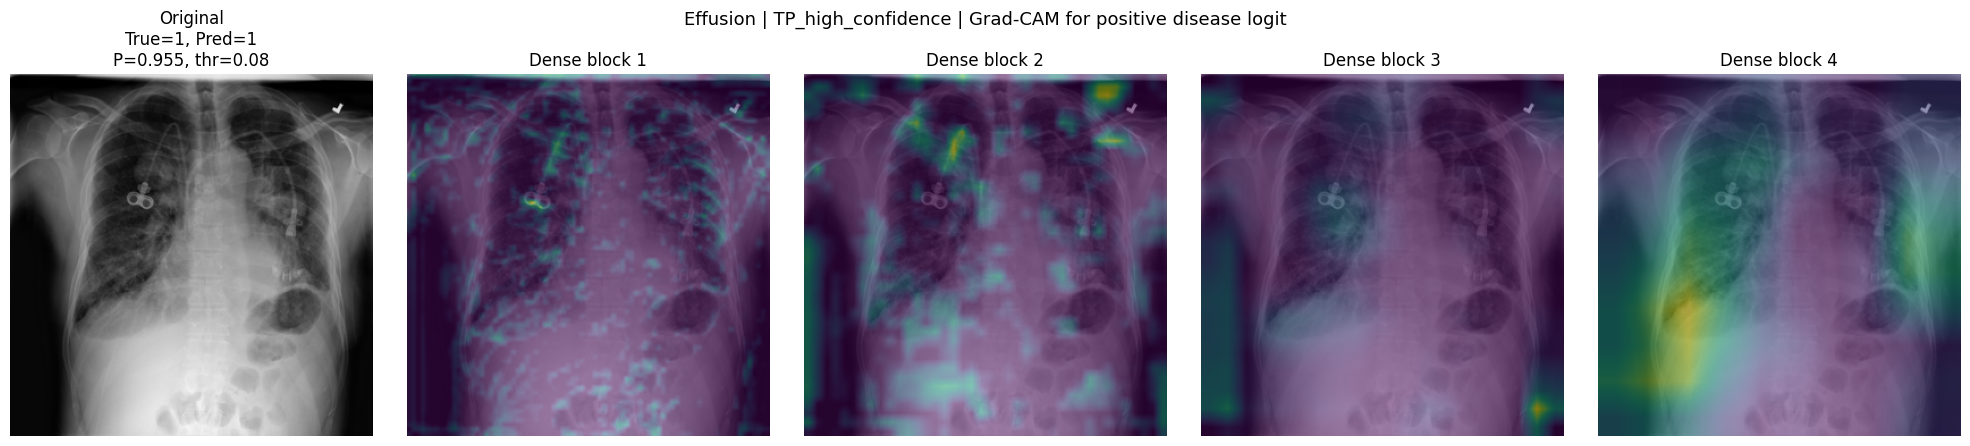

Saved: gradcam_outputs\Effusion_FP_high_confidence.png


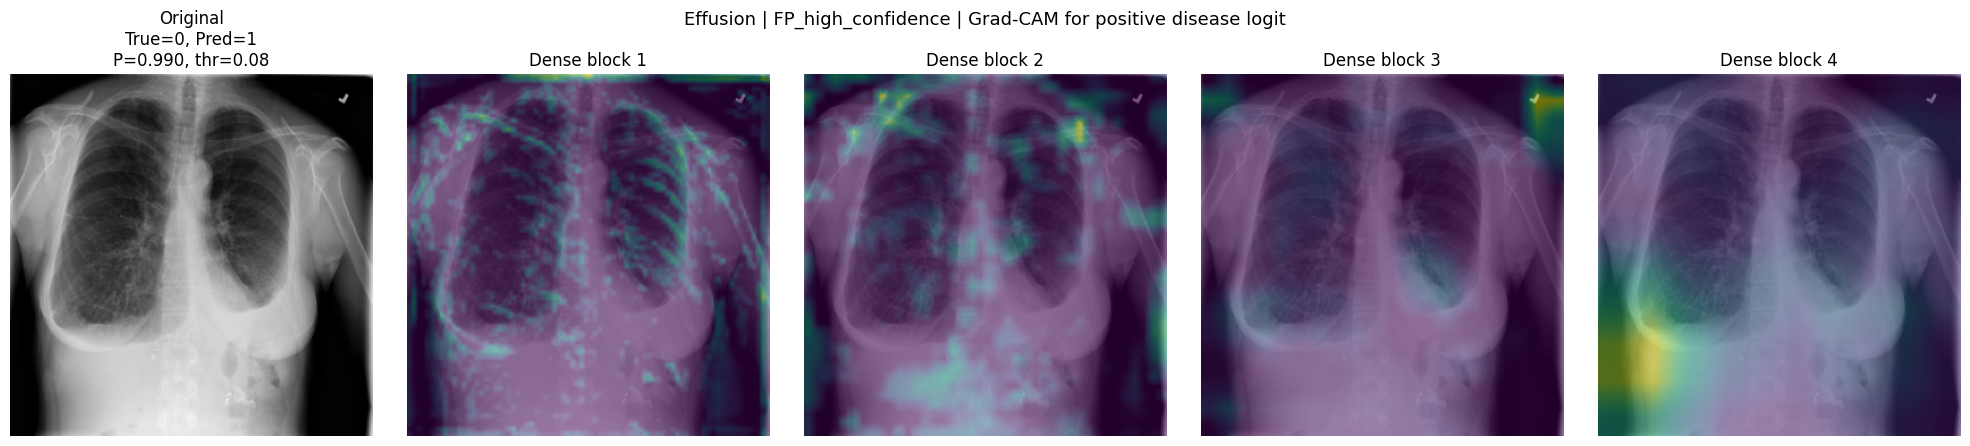

Saved: gradcam_outputs\Effusion_FN_high_probability.png


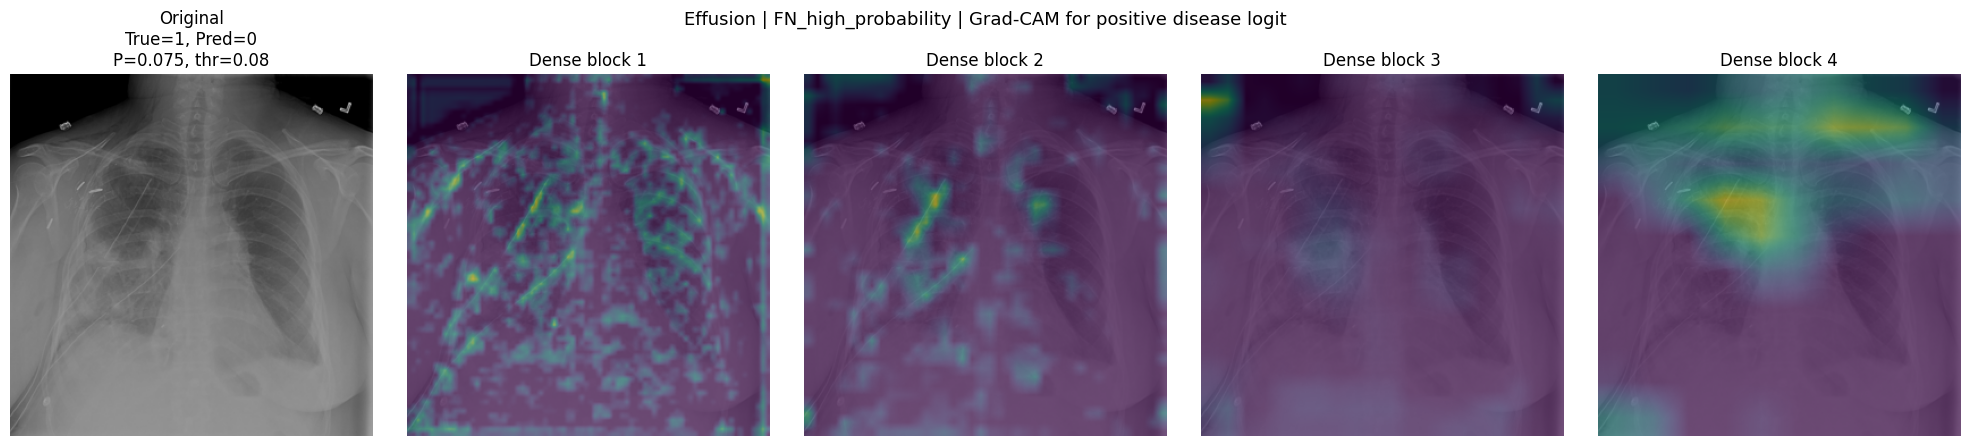

Saved: gradcam_outputs\Effusion_TN_low_probability.png


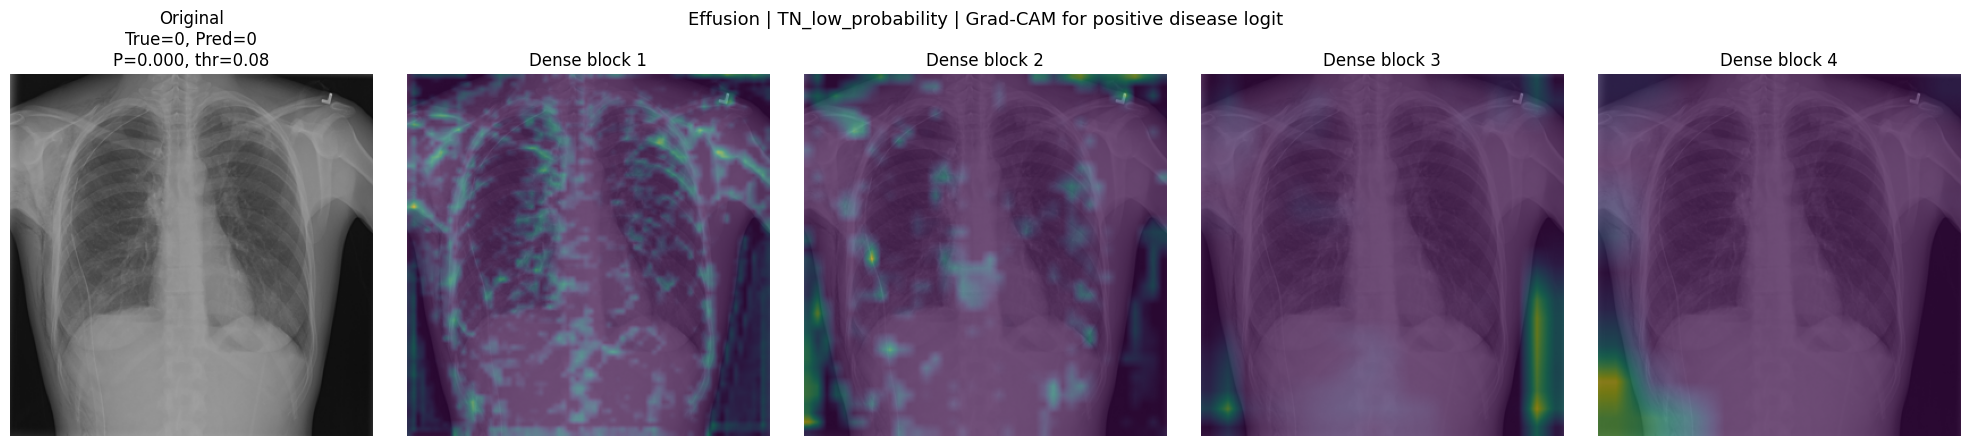


GRAD-CAM: Pneumothorax
Saved: gradcam_outputs\Pneumothorax_TP_high_confidence.png


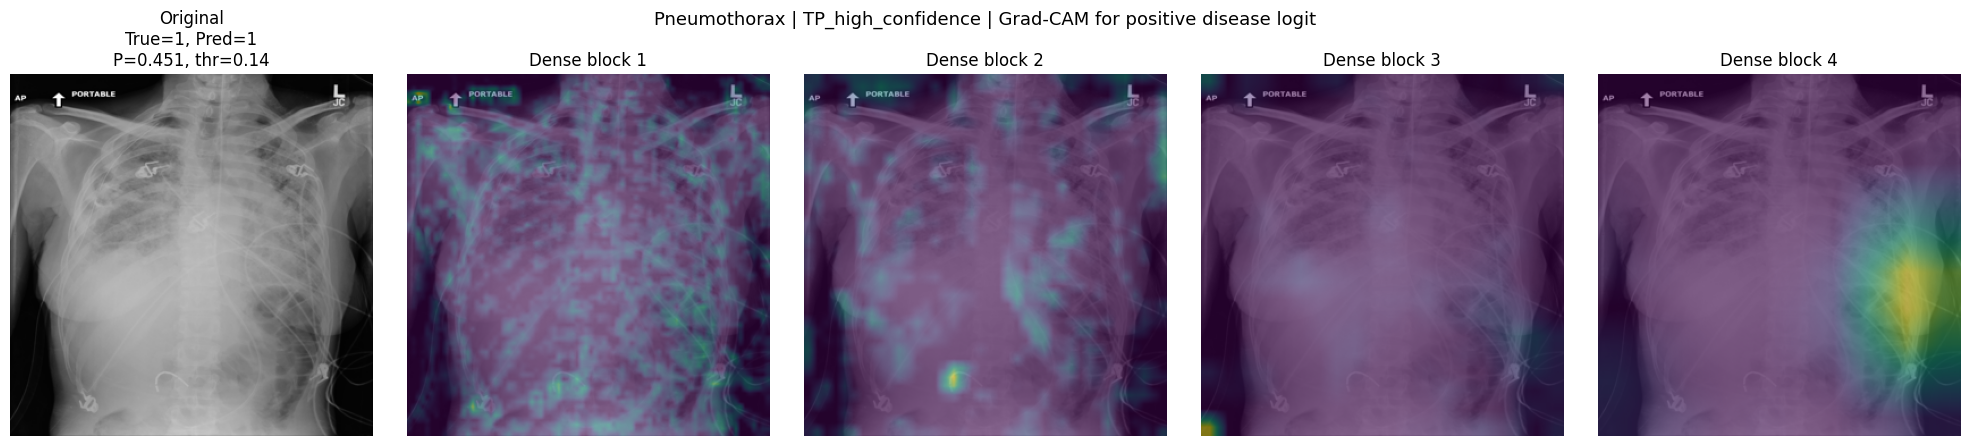

Saved: gradcam_outputs\Pneumothorax_FP_high_confidence.png


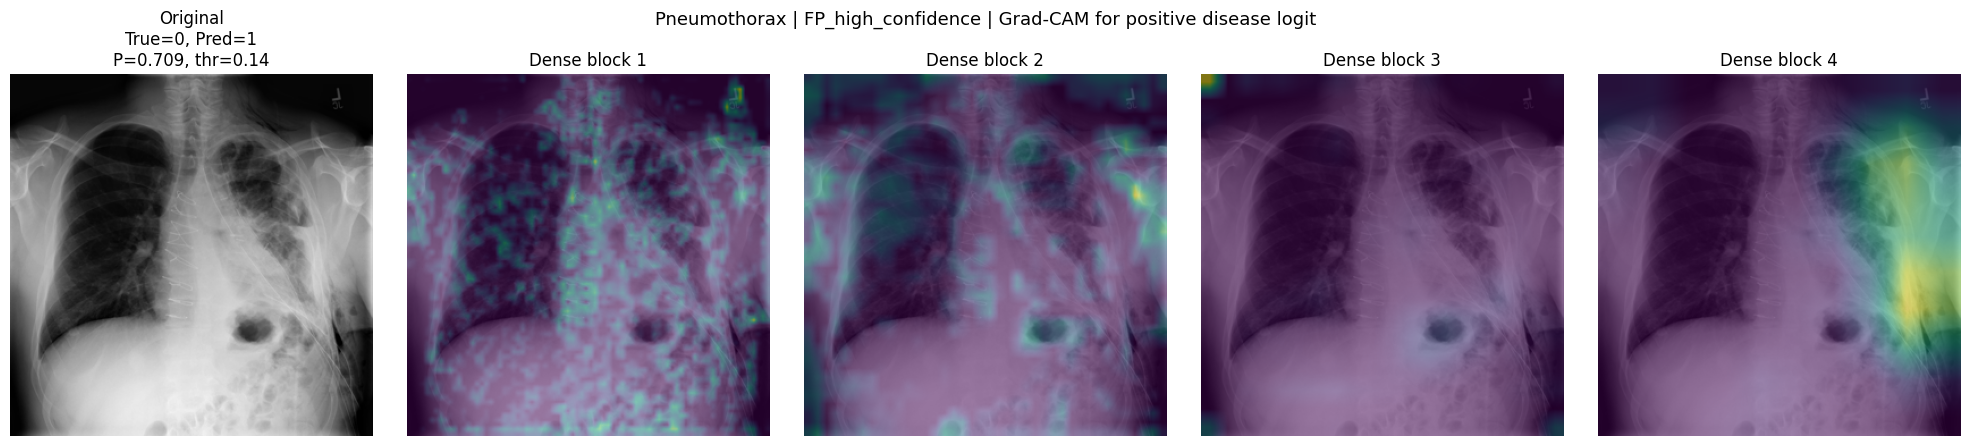

Saved: gradcam_outputs\Pneumothorax_FN_high_probability.png


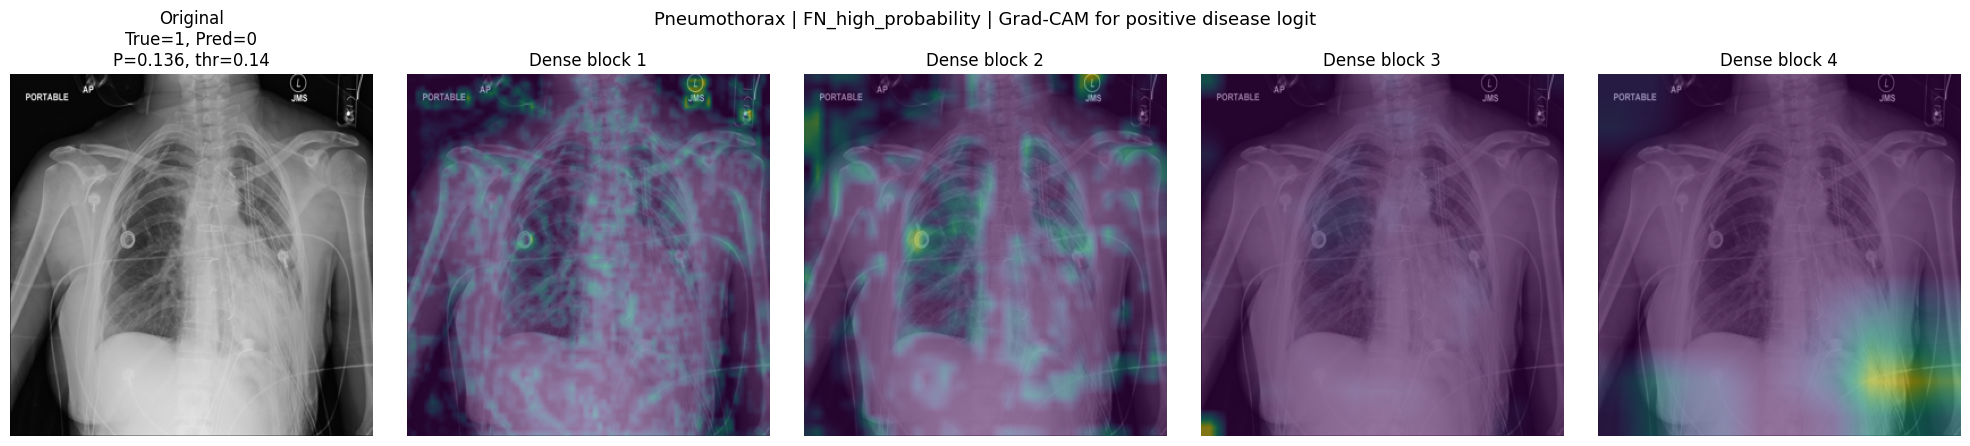

Saved: gradcam_outputs\Pneumothorax_TN_low_probability.png


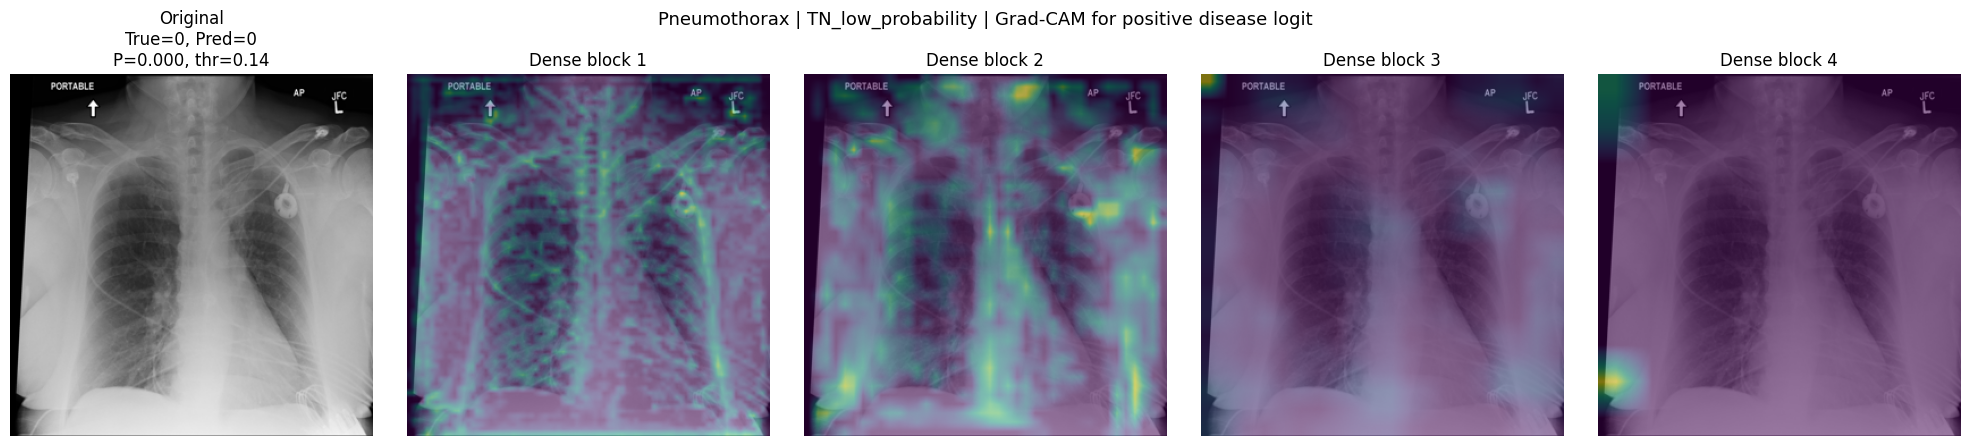

In [21]:
gradcam_results = {}

for target in TARGETS:
    print("\n" + "=" * 80)
    print("GRAD-CAM:", target)
    print("=" * 80)

    representative_cases = get_representative_cases(target)
    gradcam_results[target] = {}

    for case_name, row in representative_cases.items():
        result = show_gradcam_case(
            target_name=target,
            row=row,
            case_label=case_name,
            save=True,
        )

        gradcam_results[target][case_name] = result


## 19. Last-layer Grad-CAM summary

For a compact report figure, this section uses only **Dense block 4**, the deepest of the four inspected layers.


Saved: gradcam_outputs\Effusion_last_layer_summary.png


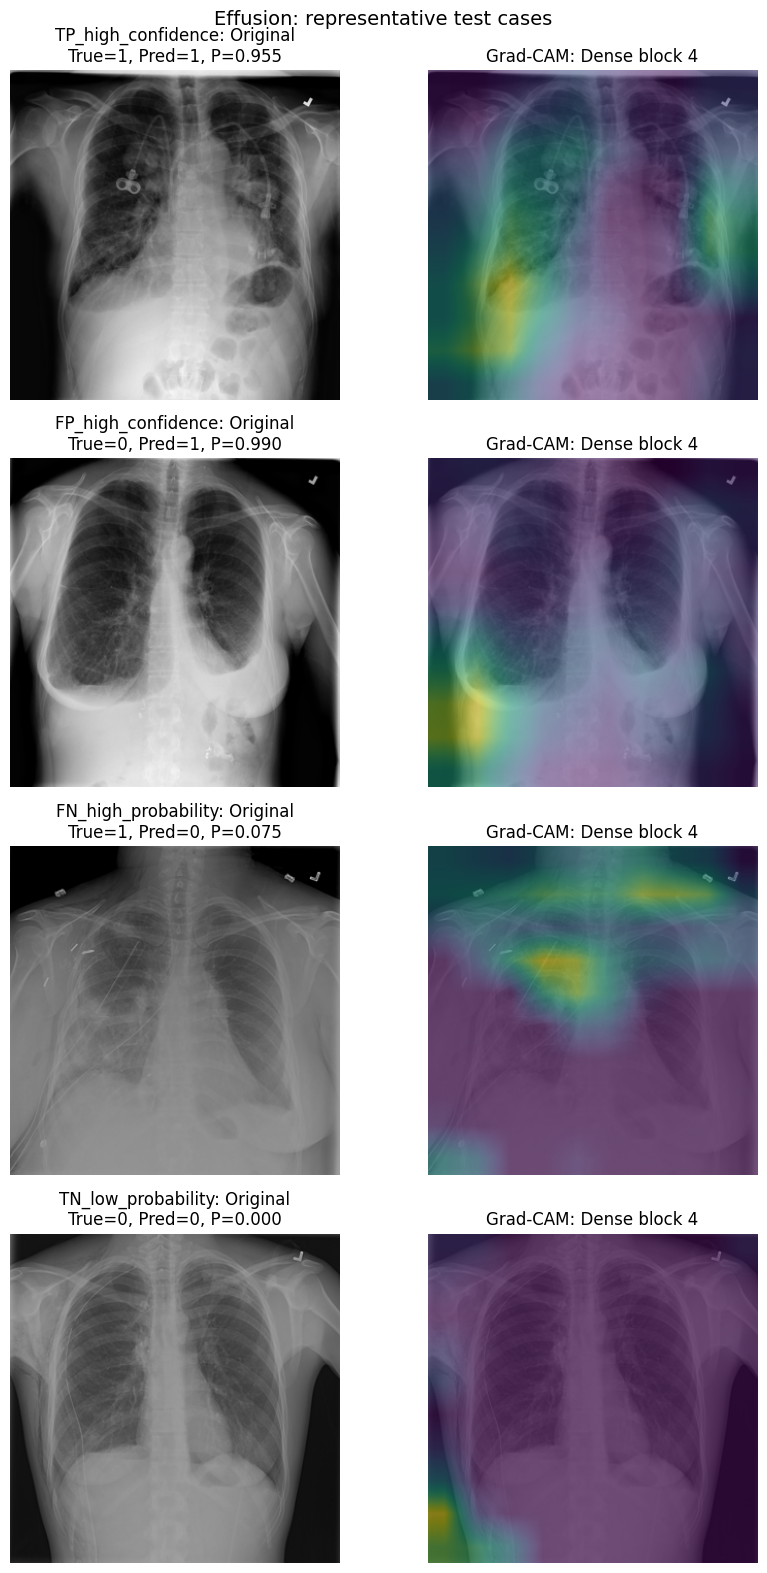

Saved: gradcam_outputs\Pneumothorax_last_layer_summary.png


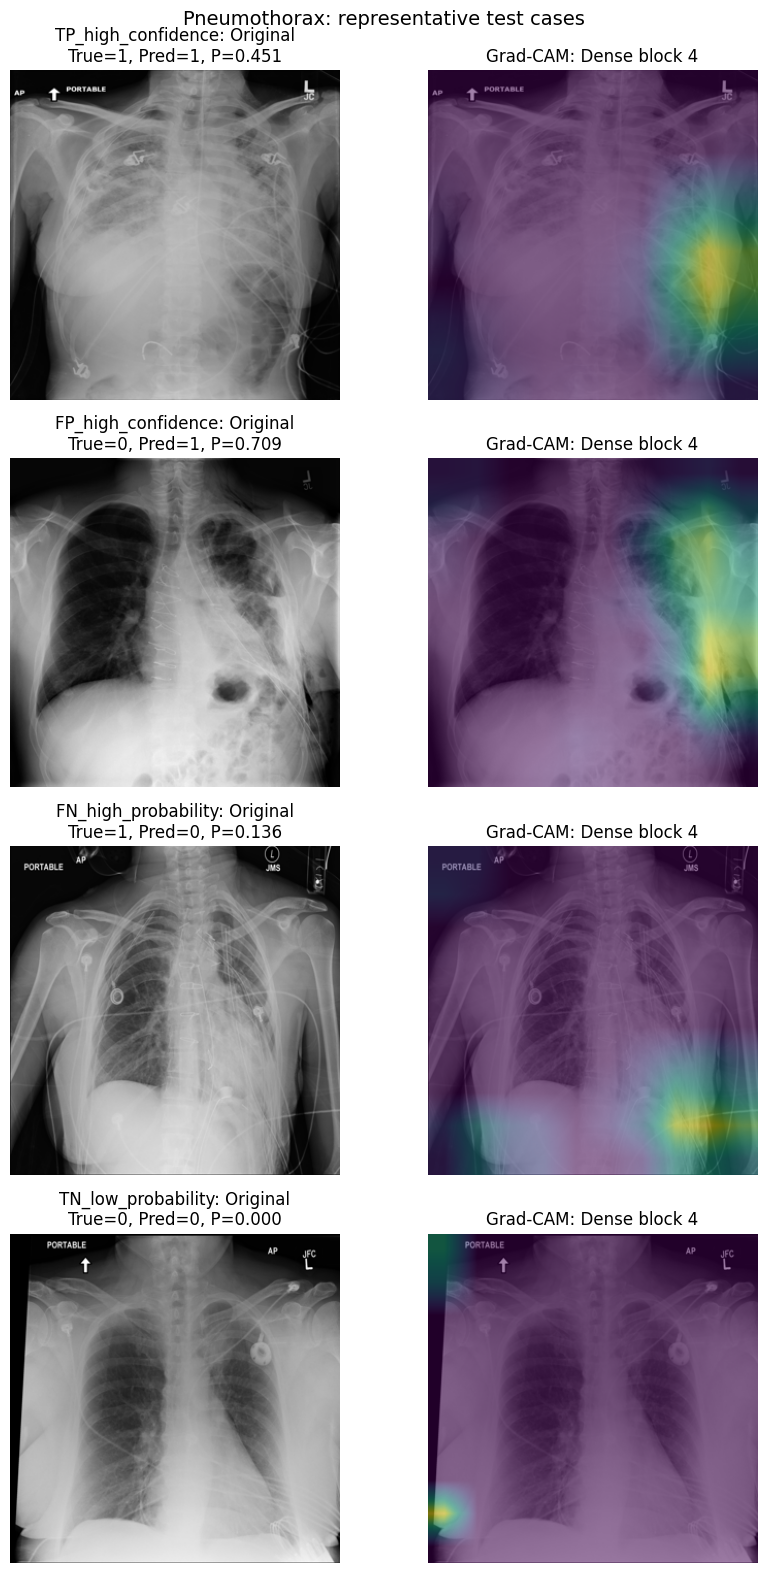

In [22]:
def show_last_layer_summary(target_name, save=True):
    representative_cases = get_representative_cases(target_name)

    if len(representative_cases) == 0:
        print(f"No representative cases for {target_name}")
        return

    n_cases = len(representative_cases)

    fig, axes = plt.subplots(
        n_cases,
        2,
        figsize=(9, 4 * n_cases),
        squeeze=False,
    )

    threshold = float(
        checkpoints[target_name]["validation_threshold"]
    )

    for row_idx, (case_name, row) in enumerate(
        representative_cases.items()
    ):
        (
            image_path,
            image_pil,
            display_image,
            input_tensor,
        ) = prepare_xai_image(row)

        cams, logit, probability = compute_gradcam_multilayer(
            models[target_name],
            input_tensor,
        )

        cam = cams["Dense block 4"]

        true_label = int(row["y_true"])
        predicted_label = int(
            probability >= threshold
        )

        axes[row_idx, 0].imshow(display_image)
        axes[row_idx, 0].set_title(
            f"{case_name}: Original\n"
            f"True={true_label}, Pred={predicted_label}, "
            f"P={probability:.3f}"
        )
        axes[row_idx, 0].axis("off")

        axes[row_idx, 1].imshow(display_image)
        axes[row_idx, 1].imshow(
            cam,
            alpha=0.5,
        )
        axes[row_idx, 1].set_title(
            "Grad-CAM: Dense block 4"
        )
        axes[row_idx, 1].axis("off")

    fig.suptitle(
        f"{target_name}: representative test cases",
        fontsize=14,
    )

    plt.tight_layout()

    if save:
        output_path = (
            GRADCAM_OUTPUT_DIR
            / f"{target_name}_last_layer_summary.png"
        )
        plt.savefig(
            output_path,
            dpi=200,
            bbox_inches="tight",
        )
        print("Saved:", output_path)

    plt.show()


for target in TARGETS:
    show_last_layer_summary(target)


## Interpretation note

Grad-CAM is a local post-hoc, model-specific attribution method. Highlighted areas indicate spatial features contributing positively to the target disease logit after gradient-weighted aggregation.

A Grad-CAM heatmap is **not automatically a clinically validated lesion localization**. For a rigorous XAI analysis, inspect multiple TP, FP, FN and TN cases and, where possible, compare highlighted regions with expert annotations or known radiographic regions of interest.


# 21. SHAP for Effusion and Pneumothorax

This section adapts the image-classification SHAP workflow from the supplied `SHAP.ipynb`.

The reference notebook:
- creates a **background set** from training images;
- initializes `shap.DeepExplainer(model, background)`;
- selects a small set of test images;
- computes `explainer.shap_values(test_samples)`;
- transposes image attributions into channels-last format;
- visualizes them with `shap.image_plot`;
- inspects the explainer expected value.

Here we use the same logic for the two trained single-target DenseNet121 models.

Because each model has a **single output logit**, the SHAP values explain the model's **positive disease logit**. Positive SHAP values push the output toward the target disease; negative SHAP values push it away from the target disease.


In [23]:
import gc

try:
    import shap
    print("SHAP version:", shap.__version__)
except ImportError as exc:
    raise ImportError(
        "The 'shap' package is required. Install it in this environment "
        "before running the SHAP section, for example with: pip install shap"
    ) from exc

SHAP_OUTPUT_DIR = Path("shap_outputs")
SHAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# DeepExplainer on 320x320 DenseNet121 images is substantially heavier
# than the MNIST example in the reference notebook.
# Start small, especially on CPU; increase later if resources allow.
SHAP_BACKGROUND_SIZE = 10

print("SHAP output directory:", SHAP_OUTPUT_DIR.resolve())
print("Background size:", SHAP_BACKGROUND_SIZE)


SHAP version: 0.52.0
SHAP output directory: C:\Users\Mahugnon\Documents\Medical Imaging\Chest X-Ray Medical Diagnosis with Deep Learning\shap_outputs
Background size: 10


## 22. Build the SHAP background set

As in the supplied SHAP notebook, the background comes from the **training set**, not the validation or test set.

The original example suggests roughly 50 to 200 background images for a small MNIST CNN. DenseNet121 with 320×320 chest X-rays is much heavier, so this notebook starts with 10 randomly selected training images. This is configurable through `SHAP_BACKGROUND_SIZE`.


In [24]:
def make_shap_background(
    target_name,
    n_background=SHAP_BACKGROUND_SIZE,
    seed=SEED,
):
    train_dataset = SingleTargetChestXrayDataset(
        train_df,
        IMAGE_DIR,
        "Image",
        target_name,
        common_transform,
    )

    rng = np.random.default_rng(seed)
    n_background = min(n_background, len(train_dataset))

    indices = rng.choice(
        len(train_dataset),
        size=n_background,
        replace=False,
    )

    background = torch.stack(
        [train_dataset[int(i)][0] for i in indices],
        dim=0,
    ).to(device)

    return background, indices


for target in TARGETS:
    bg, idx = make_shap_background(target)
    print(
        target,
        "| background:",
        tuple(bg.shape),
        "| indices:",
        idx.tolist(),
    )
    del bg
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Effusion | background: (10, 3, 320, 320) | indices: [86, 774, 89, 655, 440, 434, 702, 95, 203, 862]
Pneumothorax | background: (10, 3, 320, 320) | indices: [86, 774, 89, 655, 440, 434, 702, 95, 203, 862]


## 23. Select the same representative test cases used for Grad-CAM

For each disease, we reuse the automatically selected representative TP, FP, FN and TN cases whenever they exist. This allows direct qualitative comparison between Grad-CAM and SHAP rather than explaining unrelated images.


In [25]:
def prepare_shap_cases(target_name):
    representative_cases = get_representative_cases(target_name)

    if len(representative_cases) == 0:
        raise RuntimeError(
            f"No representative test cases found for {target_name}"
        )

    tensors = []
    display_images = []
    rows = []
    case_names = []

    for case_name, row in representative_cases.items():
        (
            image_path,
            image_pil,
            display_image,
            input_tensor,
        ) = prepare_xai_image(row)

        tensors.append(input_tensor.squeeze(0).cpu())

        # SHAP image_plot only needs an image for visualization.
        # Keep the displayed X-ray in its natural [0,1] RGB scale.
        display_np = (
            np.asarray(display_image).astype(np.float32) / 255.0
        )
        display_images.append(display_np)

        rows.append(row)
        case_names.append(case_name)

    test_samples = torch.stack(tensors, dim=0).to(device)
    display_images = np.stack(display_images, axis=0)

    return (
        test_samples,
        display_images,
        rows,
        case_names,
    )


for target in TARGETS:
    samples, display_images, rows, case_names = prepare_shap_cases(
        target
    )
    print(
        target,
        "| samples:",
        tuple(samples.shape),
        "| cases:",
        case_names,
    )


Effusion | samples: (4, 3, 320, 320) | cases: ['TP_high_confidence', 'FP_high_confidence', 'FN_high_probability', 'TN_low_probability']
Pneumothorax | samples: (4, 3, 320, 320) | cases: ['TP_high_confidence', 'FP_high_confidence', 'FN_high_probability', 'TN_low_probability']


## 24. Robust helper for single-output SHAP arrays

Depending on the installed SHAP version, PyTorch `DeepExplainer.shap_values()` may return either:
- a list containing one array for the single output; or
- a NumPy array with an explicit final output dimension.

This helper converts both forms to a common `[N, C, H, W]` representation.


In [26]:
def normalize_single_output_shap(shap_values):
    if isinstance(shap_values, list):
        if len(shap_values) != 1:
            raise ValueError(
                "Expected one SHAP output for the single-logit model, "
                f"but received {len(shap_values)} outputs."
            )
        values = np.asarray(shap_values[0])
    else:
        values = np.asarray(shap_values)

    # Newer SHAP versions may return [N, C, H, W, 1].
    if values.ndim == 5 and values.shape[-1] == 1:
        values = values[..., 0]

    if values.ndim != 4:
        raise ValueError(
            "Expected SHAP values with shape [N,C,H,W] "
            "or [N,C,H,W,1], but got "
            f"{values.shape}"
        )

    return values


## 25. Run SHAP DeepExplainer

This follows the reference notebook's `shap.DeepExplainer(model, background)` workflow.

For computational safety, the explainer is built and released **one disease at a time**. No model retraining occurs.


## 25. DenseNet121 compatibility fix for SHAP DeepExplainer

`shap.DeepExplainer` installs backward hooks. Torchvision DenseNet121 uses several in-place ReLU operations, including a final functional ReLU in `DenseNet.forward`. With recent PyTorch versions this can raise:

```text
RuntimeError: Output 0 of BackwardHookFunction is a view and is being modified inplace
```

The fix below does **not retrain or change the learned weights**. It:
1. changes all `nn.ReLU` modules to `inplace=False`;
2. uses a small wrapper that reproduces DenseNet121's forward pass but replaces the final `F.relu(..., inplace=True)` with `inplace=False`;
3. verifies that the SHAP-safe model produces the same logits as the original model before explanations are computed.


In [27]:
class DenseNet121ForSHAP(nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.features = base_model.features
        self.classifier = base_model.classifier

    def forward(self, x):
        features = self.features(x)

        # Torchvision DenseNet.forward uses an in-place functional ReLU.
        # SHAP DeepExplainer backward hooks are incompatible with that
        # operation in recent PyTorch versions, so use an out-of-place ReLU.
        out = F.relu(features, inplace=False)
        out = F.adaptive_avg_pool2d(out, (1, 1))
        out = torch.flatten(out, 1)
        out = self.classifier(out)
        return out


def make_shap_compatible_model(base_model):
    # Convert all module-level in-place ReLUs inside DenseNet features.
    # This changes only how activations are stored, not the learned weights.
    for module in base_model.modules():
        if isinstance(module, nn.ReLU):
            module.inplace = False

    shap_model = DenseNet121ForSHAP(base_model)
    shap_model = shap_model.to(device)
    shap_model.eval()
    return shap_model


In [28]:
def compute_shap_for_target(
    target_name,
    n_background=SHAP_BACKGROUND_SIZE,
):
    base_model = models[target_name]
    base_model.eval()

    background, background_indices = make_shap_background(
        target_name,
        n_background=n_background,
        seed=SEED,
    )

    (
        test_samples,
        display_images,
        rows,
        case_names,
    ) = prepare_shap_cases(target_name)

    # Build a SHAP-safe DenseNet forward graph.
    # No weights are changed and no retraining occurs.
    shap_model = make_shap_compatible_model(base_model)

    # Verify that replacing in-place ReLUs did not alter predictions.
    with torch.no_grad():
        # The base_model's module-level ReLUs have also been made out-of-place.
        # Its own forward still contains the final functional in-place ReLU,
        # so compare with the wrapper on a cloned input before DeepExplainer hooks.
        original_logits = base_model(test_samples.clone()).squeeze(1)
        safe_logits = shap_model(test_samples.clone()).squeeze(1)

        max_logit_difference = (
            original_logits - safe_logits
        ).abs().max().item()

    print(
        f"{target_name}: max |original logit - SHAP-safe logit| = "
        f"{max_logit_difference:.3e}"
    )

    if max_logit_difference > 1e-5:
        raise RuntimeError(
            "SHAP-safe DenseNet does not reproduce the original model "
            f"closely enough (max difference={max_logit_difference:.3e})."
        )

    print(
        f"{target_name}: building DeepExplainer with "
        f"{len(background)} background images..."
    )

    explainer = shap.DeepExplainer(
        shap_model,
        background,
    )

    try:
        raw_shap_values = explainer.shap_values(
            test_samples,
            check_additivity=False,
        )
    except TypeError:
        # Compatibility with older SHAP versions.
        raw_shap_values = explainer.shap_values(
            test_samples
        )

    shap_nchw = normalize_single_output_shap(
        raw_shap_values
    )

    with torch.no_grad():
        logits = (
            shap_model(test_samples)
            .squeeze(1)
            .detach()
            .cpu()
            .numpy()
        )

        probabilities = 1.0 / (
            1.0 + np.exp(-logits)
        )

    expected_value = np.asarray(
        explainer.expected_value
    ).reshape(-1)[0]

    result = {
        "target": target_name,
        "background_indices": background_indices,
        "test_samples": test_samples.detach().cpu(),
        "display_images": display_images,
        "rows": rows,
        "case_names": case_names,
        "shap_nchw": shap_nchw,
        "logits": logits,
        "probabilities": probabilities,
        "expected_value": float(expected_value),
        "max_logit_difference": max_logit_difference,
    }

    # Release the heavy explainer/background references.
    del explainer, background, raw_shap_values, shap_model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


## 26. Compute SHAP for both diseases

This is the computationally expensive part of the SHAP section. On CPU it can take noticeably longer than Grad-CAM.


### Run the corrected SHAP computation

If the compatibility fix is working, each disease should first print a near-zero `max |original logit - SHAP-safe logit|`, then proceed to `building DeepExplainer...` without the in-place ReLU runtime error.


In [29]:
shap_results = {}

for target in TARGETS:
    print("\n" + "=" * 80)
    print("SHAP:", target)
    print("=" * 80)

    shap_results[target] = compute_shap_for_target(
        target_name=target,
        n_background=SHAP_BACKGROUND_SIZE,
    )

    result = shap_results[target]

    print("Expected value:", result["expected_value"])
    for case_name, prob in zip(
        result["case_names"],
        result["probabilities"],
    ):
        print(
            f"{case_name}: disease probability={prob:.4f}"
        )



SHAP: Effusion
Effusion: max |original logit - SHAP-safe logit| = 0.000e+00
Effusion: building DeepExplainer with 10 background images...
Expected value: -3.895448684692383
TP_high_confidence: disease probability=0.9551
FP_high_confidence: disease probability=0.9898
FN_high_probability: disease probability=0.0751
TN_low_probability: disease probability=0.0004

SHAP: Pneumothorax
Pneumothorax: max |original logit - SHAP-safe logit| = 0.000e+00
Pneumothorax: building DeepExplainer with 10 background images...
Expected value: -5.141016483306885
TP_high_confidence: disease probability=0.4510
FP_high_confidence: disease probability=0.7090
FN_high_probability: disease probability=0.1364
TN_low_probability: disease probability=0.0004


## 27. SHAP image plots

The reference SHAP notebook transposes the image SHAP values from channels-first to channels-last before calling `shap.image_plot`.

We do the same here:
`[N,C,H,W] -> [N,H,W,C]`.

Each row label reports the case type and the trained model's disease probability.


Saved: shap_outputs\Effusion_SHAP_representative_cases.png


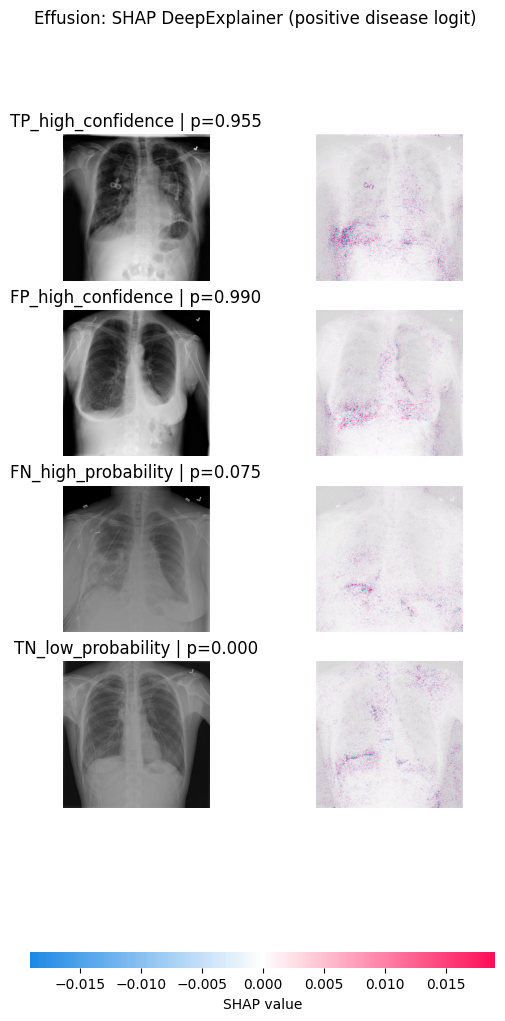

Saved: shap_outputs\Pneumothorax_SHAP_representative_cases.png


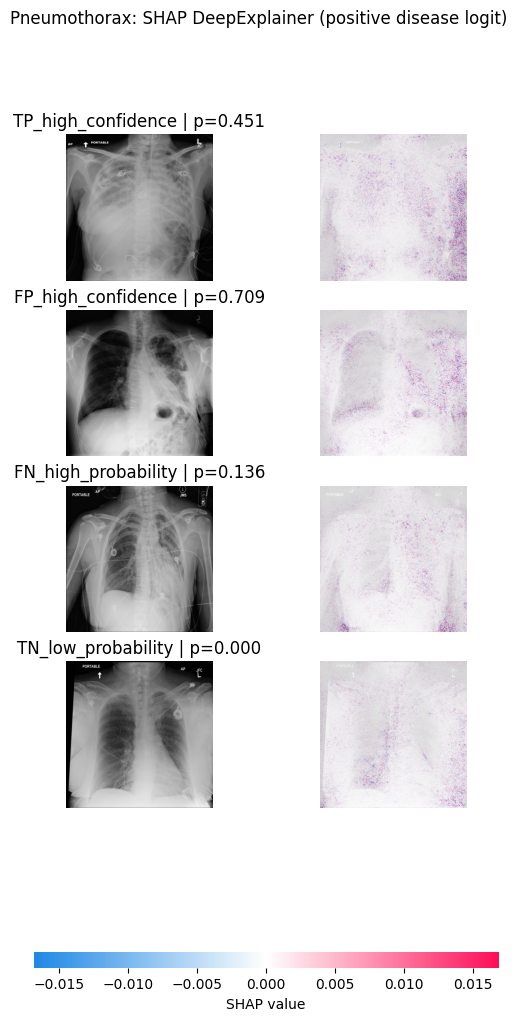

In [30]:
def show_shap_image_plot(target_name, save=True):
    result = shap_results[target_name]

    shap_nhwc = np.transpose(
        result["shap_nchw"],
        (0, 2, 3, 1),
    )

    row_labels = [
        f"{case_name} | p={prob:.3f}"
        for case_name, prob in zip(
            result["case_names"],
            result["probabilities"],
        )
    ]

    # Single model output -> one SHAP output list for image_plot.
    shap_for_plot = [shap_nhwc]

    shap.image_plot(
        shap_for_plot,
        result["display_images"],
        true_labels=row_labels,
        show=False,
    )

    plt.suptitle(
        f"{target_name}: SHAP DeepExplainer "
        "(positive disease logit)",
    )

    if save:
        output_path = (
            SHAP_OUTPUT_DIR
            / f"{target_name}_SHAP_representative_cases.png"
        )
        plt.savefig(
            output_path,
            dpi=200,
            bbox_inches="tight",
        )
        print("Saved:", output_path)

    plt.show()


for target in TARGETS:
    show_shap_image_plot(target)


## 28. SHAP expected value and local additivity diagnostic

The supplied SHAP notebook inspects the expected value and compares:

`base value + sum(SHAP values)`

with the model output.

The same diagnostic is performed here in **logit space**, because the single-target DenseNet121 outputs one raw logit.


In [31]:
def shap_additivity_table(target_name):
    result = shap_results[target_name]

    base_value = result["expected_value"]

    rows = []
    for i, case_name in enumerate(
        result["case_names"]
    ):
        shap_sum = float(
            np.asarray(
                result["shap_nchw"][i]
            ).sum()
        )

        reconstructed_logit = (
            base_value + shap_sum
        )
        model_logit = float(
            result["logits"][i]
        )

        rows.append({
            "Disease": target_name,
            "Case": case_name,
            "Expected_Value": base_value,
            "Sum_SHAP": shap_sum,
            "Base_plus_SHAP": reconstructed_logit,
            "Model_Logit": model_logit,
            "Absolute_Difference": abs(
                reconstructed_logit - model_logit
            ),
        })

    return pd.DataFrame(rows)


shap_additivity_results = pd.concat(
    [
        shap_additivity_table(target)
        for target in TARGETS
    ],
    ignore_index=True,
)

shap_additivity_results


,Disease,Case,Expected_Value,Sum_SHAP,Base_plus_SHAP,Model_Logit,Absolute_Difference
0,Effusion,TP_high_confidence,-3.895449,3.984152,0.088703,3.056369,2.967666
1,Effusion,FP_high_confidence,-3.895449,4.661801,0.766352,4.577466,3.811114
2,Effusion,FN_high_probability,-3.895449,0.914379,-2.981069,-2.510488,0.470581
3,Effusion,TN_low_probability,-3.895449,-2.125192,-6.020641,-7.779881,1.759241
4,Pneumothorax,TP_high_confidence,-5.141016,2.883150,-2.257866,-0.196667,2.061199
5,Pneumothorax,FP_high_confidence,-5.141016,3.238349,-1.902667,0.890374,2.793042
6,Pneumothorax,FN_high_probability,-5.141016,1.650416,-3.490601,-1.845608,1.644992
7,Pneumothorax,TN_low_probability,-5.141016,-1.483749,-6.624765,-7.767894,1.143129


## 29. Save SHAP numerical outputs

The raw SHAP arrays can be much more useful than only saving figures. They allow later quantitative or case-specific analyses without rerunning `DeepExplainer`.


In [32]:
SHAP_ARRAY_DIR = SHAP_OUTPUT_DIR / "arrays"
SHAP_ARRAY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

for target in TARGETS:
    result = shap_results[target]

    np.save(
        SHAP_ARRAY_DIR / f"{target}_shap_values.npy",
        result["shap_nchw"],
    )

    np.save(
        SHAP_ARRAY_DIR / f"{target}_probabilities.npy",
        result["probabilities"],
    )

    pd.DataFrame({
        "Case": result["case_names"],
        "Image": [
            row["Image"]
            for row in result["rows"]
        ],
        "Probability": result["probabilities"],
        "Model_Logit": result["logits"],
    }).to_csv(
        SHAP_ARRAY_DIR / f"{target}_cases.csv",
        index=False,
    )

shap_additivity_results.to_csv(
    SHAP_OUTPUT_DIR / "shap_additivity_check.csv",
    index=False,
)

print("Saved SHAP arrays and metadata.")


Saved SHAP arrays and metadata.


# 30. Grad-CAM and SHAP together

The two methods answer related but different questions:

- **Grad-CAM** highlights coarse spatial regions in deep convolutional feature maps that support the positive disease logit.
- **SHAP DeepExplainer** assigns signed local contributions to input pixels/channels relative to a training-image background distribution.

Agreement between the two methods can strengthen a qualitative interpretation, while disagreement is itself informative. Neither method alone establishes clinically correct lesion localization.

For the final XAI analysis, compare the same TP, FP, FN and TN cases for **Effusion** and **Pneumothorax**, rather than presenting only the most visually convincing examples.
